# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

## Preprocessing

In [28]:
# some helper functions and classes (no need to check them now)
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [29]:

outcome_space = part1.clslib.NamedClasses(['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])
print(outcome_space)

0: sadness, 1: joy, 2: love, 3: anger, 4: fear, 5: surprise


In [30]:
from datasets import load_dataset, concatenate_datasets

#Loading our training corpus
# dataset = load_dataset("stanfordnlp/sst2")
dataset = load_dataset("dair-ai/emotion", "split")

### Merge Validation set with Training set.

In [31]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [32]:
dataset["train"] = concatenate_datasets([dataset['train'], dataset['validation']])
print(dataset)
del dataset["validation"]
print(dataset)


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 18000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 18000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [33]:
#An example of an article from our training corpus
print("---- Negative Example ----")
print("Text:", dataset["train"]["text"][0])
print("Gold label (id):", dataset["train"]["label"][0])
print("Gold label (name):", outcome_space.name(dataset["train"]["label"][0]))

print("---- Positive Example ----")
#An example of an article from our training corpus
print("Text:", dataset["train"]["text"][2])
print("Gold label (id):", dataset["train"]["label"][2])
print("Gold label (name):", outcome_space.name(dataset["train"]["label"][2]))


---- Negative Example ----
Text: i didnt feel humiliated
Gold label (id): 0
Gold label (name): sadness
---- Positive Example ----
Text: im grabbing a minute to post i feel greedy wrong
Gold label (id): 3
Gold label (name): anger


---- train Set ----
Total examples: 18000
Sadness: 5216 examples (28.98%)
Joy: 6066 examples (33.70%)
Love: 1482 examples (8.23%)
Anger: 2434 examples (13.52%)
Fear: 2149 examples (11.94%)
Surprise: 653 examples (3.63%)


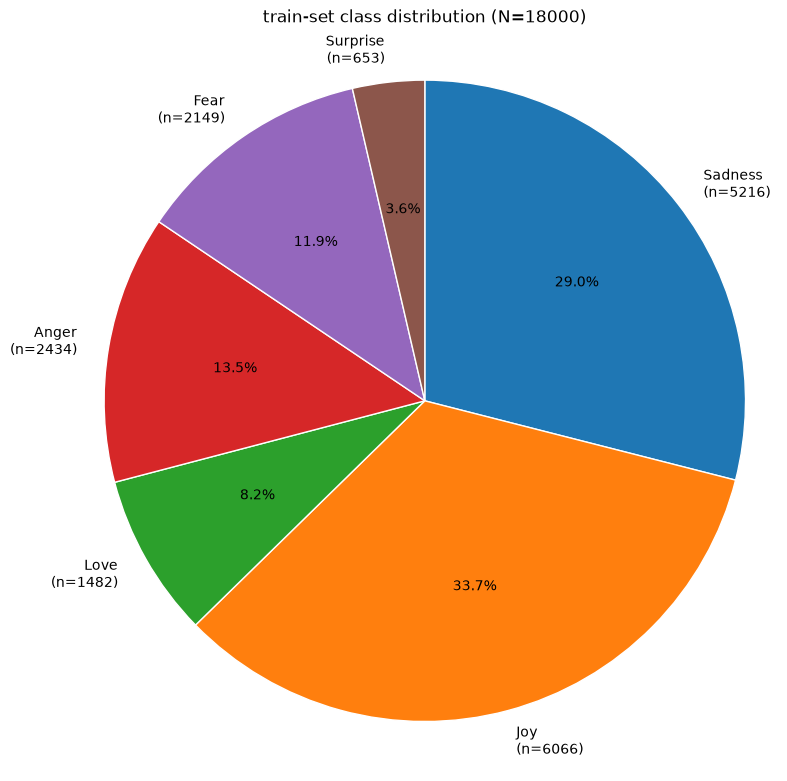

---- test Set ----
Total examples: 2000
Sadness: 581 examples (29.05%)
Joy: 695 examples (34.75%)
Love: 159 examples (7.95%)
Anger: 275 examples (13.75%)
Fear: 224 examples (11.20%)
Surprise: 66 examples (3.30%)


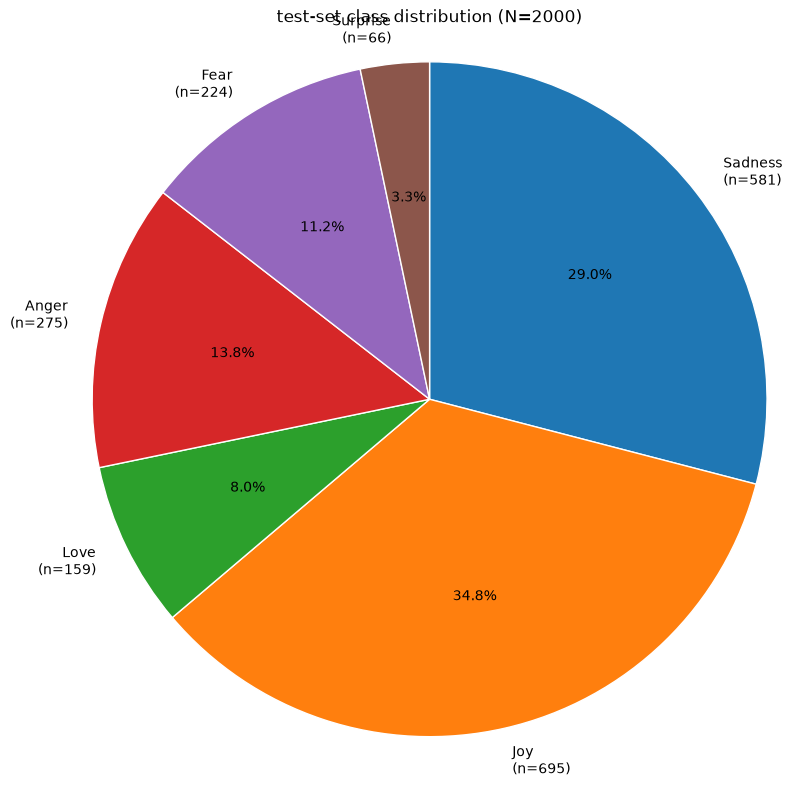

In [34]:
import matplotlib.pyplot as plt
import numpy as np
for split_name in ['train', 'test']:
    labels = np.array(dataset[split_name]["label"])
    class_names = outcome_space.names
    num_classes = len(class_names)

    class_counts = np.bincount(labels, minlength=num_classes)
    class_percentages = class_counts / labels.size * 100

    print(f"---- {split_name} Set ----")
    print(f"Total examples: {labels.size}")

    for label_id, label_name in enumerate(class_names):
        print(
            f"{label_name.title()}: "
            f"{class_counts[label_id]} examples "
            f"({class_percentages[label_id]:.2f}%)"
        )

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.pie(
        class_counts,
        labels=[
            f"{name.title()}\n(n={count})"
            for name, count in zip(class_names, class_counts)
        ],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1,
        },
    )

    ax.set_title(f"{split_name}-set class distribution (N={labels.size})")
    ax.axis("equal")  # Keep the pie circular

    plt.tight_layout()
    plt.show()

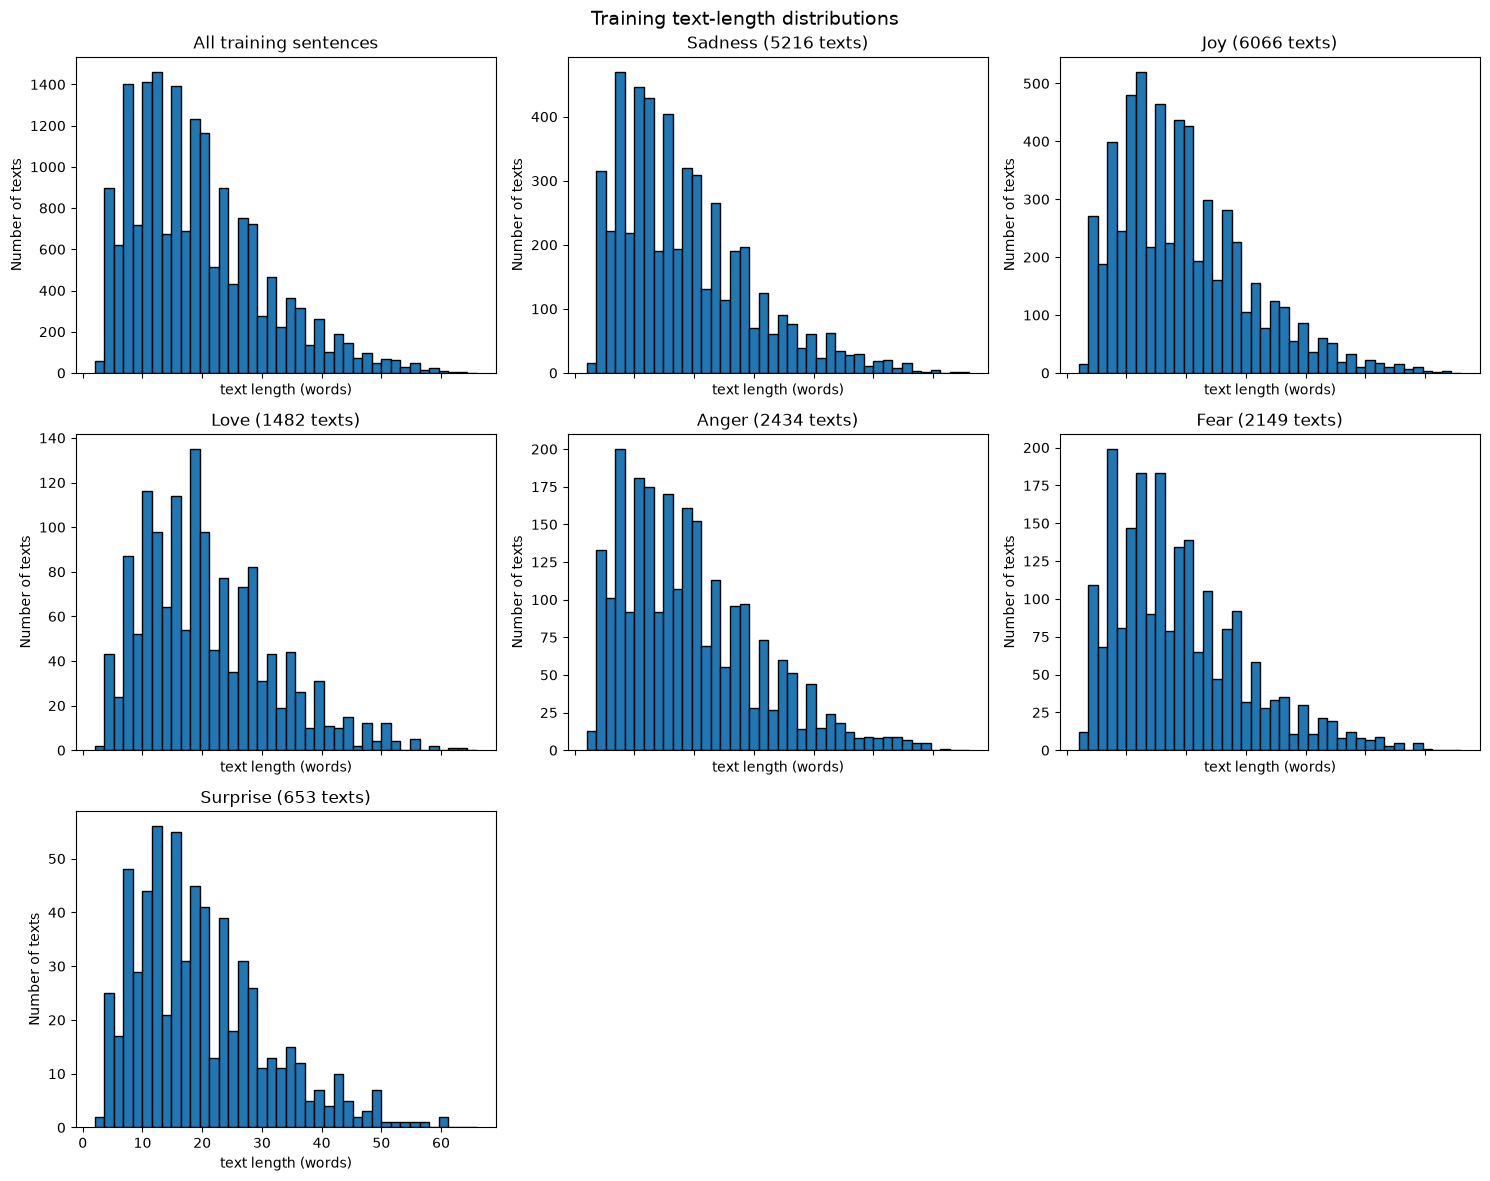

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import math

train_texts = dataset["train"]["text"]
labels = np.array(dataset["train"]["label"])

text_lengths = np.array([
    len(text.split())
    for text in train_texts
])

num_classes = len(outcome_space.names)
num_plots = num_classes + 1  # All data + one plot per class

ncols = 3
nrows = math.ceil(num_plots / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(5 * ncols, 4 * nrows),
    sharex=True,
)

axes = np.atleast_1d(axes).flatten()

# Use identical bins so the plots are directly comparable
bin_edges = np.histogram_bin_edges(text_lengths, bins=40)

# First plot: entire training set
axes[0].hist(
    text_lengths,
    bins=bin_edges,
    edgecolor="black",
)

axes[0].set_title("All training sentences")
axes[0].set_xlabel("text length (words)")
axes[0].set_ylabel("Number of texts")

# Remaining plots: one for each class
for label_id, label_name in enumerate(outcome_space.names):
    ax = axes[label_id + 1]
    class_lengths = text_lengths[labels == label_id]

    ax.hist(
        class_lengths,
        bins=bin_edges,
        edgecolor="black",
    )

    ax.set_title(f"{label_name.title()} ({len(class_lengths)} texts)")
    ax.set_xlabel("text length (words)")
    ax.set_ylabel("Number of texts")

# Hide unused subplot positions
for ax in axes[num_plots:]:
    ax.set_visible(False)

fig.suptitle(
    "Training text-length distributions",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## Tokenizer

In [36]:
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.trainers import WordLevelTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import Lowercase

corpus = dataset["train"]["text"]
choice = "word-level"

if choice == "bpe":
    vocab_size = 1000

    # min_frequency=2 means a pair must occur at least twice in the training corpus before it can be merged.
    min_frequency = 2

    tokenizer = part1.experiment.train_tokenizer(
        corpus,
        vocab_size,
        min_frequency
    )

if choice == "word-level":
    vocab_size = 1000
    min_frequency = 2
    unk_token = "??"
    
    # Word-level tokenizer that maps each known complete word
    # to one token ID.
    tokenizer = Tokenizer(WordLevel(unk_token=unk_token))
    
    # Convert text to lowercase during both training and later encoding.
    # This does not modify the original text strings.
    tokenizer.normalizer = Lowercase()

    # Split normalized text into words and punctuation before vocabulary lookup.
    tokenizer.pre_tokenizer = Whitespace()

    # Configure how the word-level vocabulary will be learned.
    trainer = WordLevelTrainer(
        vocab_size=vocab_size,
        min_frequency=min_frequency,
        special_tokens=[unk_token],
    )

    tokenizer.train_from_iterator(corpus, trainer=trainer)

text = corpus[0]
encoded = tokenizer.encode(text)

print("Original text:")
print(text)

print("\nWord-level tokens:")
print(encoded.tokens)

print("\nToken IDs:")
print(encoded.ids)

Original text:
i didnt feel humiliated

Word-level tokens:
['i', 'didnt', 'feel', 'humiliated']

Token IDs:
[1, 139, 2, 659]


Unique normalized tokens in the training dataset: 16,196
Tokens occurring at least 2 times: 7,902
WordLevel vocabulary cap: 1,000 total tokens (999 dataset tokens + 1 special token)
Actual learned vocabulary size: 1,000
Eligible dataset tokens excluded because of the cap: 6,903


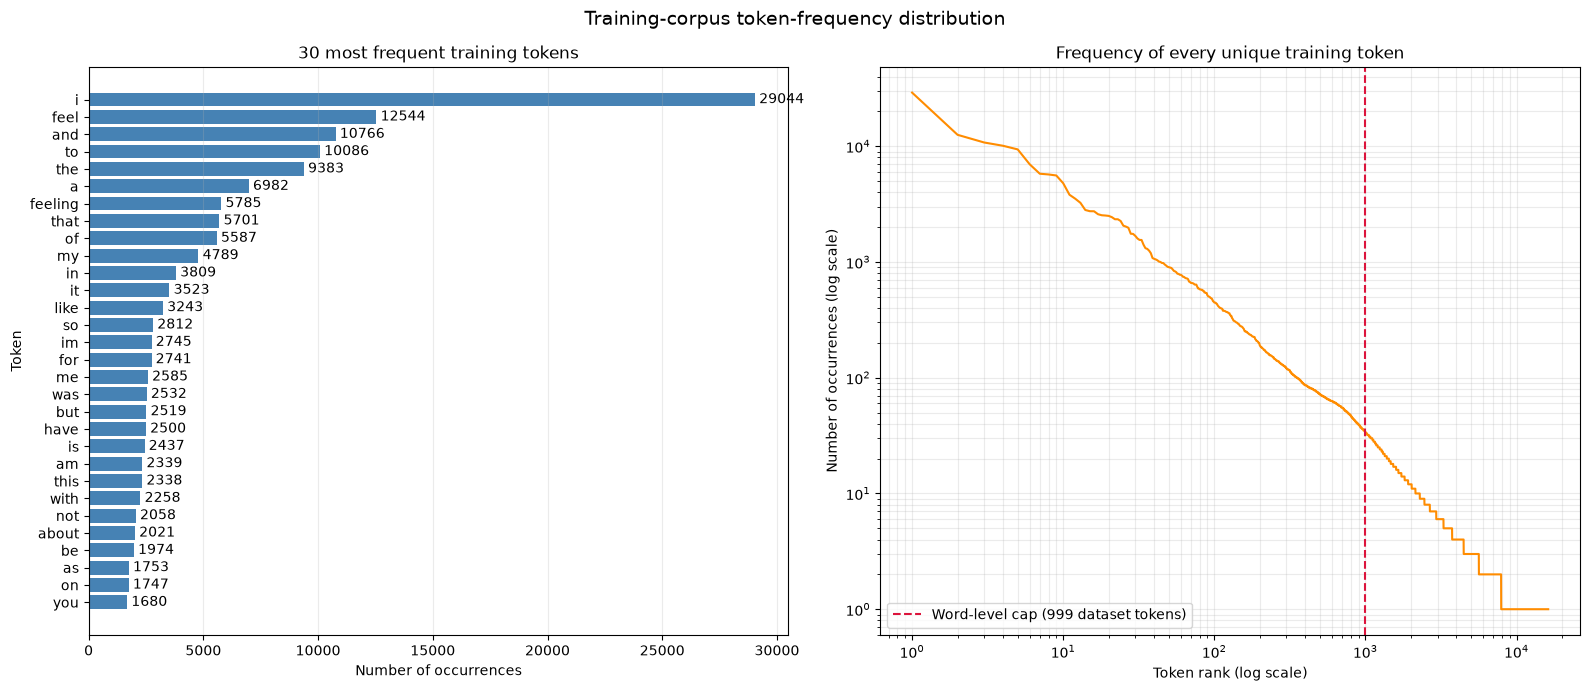

In [37]:
from collections import Counter
import matplotlib.pyplot as plt

# Count tokens using exactly the same normalization and pre-tokenization
# as the WordLevel tokenizer. Only the training corpus is inspected so the
# test set remains unseen.
word_counts = Counter()
for document in corpus:
    normalized = tokenizer.normalizer.normalize_str(document)
    tokens_with_offsets = tokenizer.pre_tokenizer.pre_tokenize_str(normalized)
    word_counts.update(token for token, _ in tokens_with_offsets)

num_unique_words = len(word_counts)
num_eligible_words = sum(
    frequency >= min_frequency for frequency in word_counts.values()
)
num_special_tokens = 1  # The unknown token: ??
word_level_cap = vocab_size - num_special_tokens
num_words_removed_by_cap = max(0, num_eligible_words - word_level_cap)

print(f"Unique normalized tokens in the training dataset: {num_unique_words:,}")
print(
    f"Tokens occurring at least {min_frequency} times: "
    f"{num_eligible_words:,}"
)
print(
    f"WordLevel vocabulary cap: {vocab_size:,} total tokens "
    f"({word_level_cap:,} dataset tokens + {num_special_tokens} special token)"
)
print(f"Actual learned vocabulary size: {len(tokenizer.get_vocab()):,}")
print(
    f"Eligible dataset tokens excluded because of the cap: "
    f"{num_words_removed_by_cap:,}"
)

# Show identifiable high-frequency words and the distribution of every word.
top_n = 30
top_words = word_counts.most_common(top_n)
words, counts = zip(*reversed(top_words))
all_counts = sorted(word_counts.values(), reverse=True)
ranks = range(1, len(all_counts) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

bars = axes[0].barh(words, counts, color="steelblue")
axes[0].bar_label(bars, padding=3, fmt="%d")
axes[0].set_title(f"{top_n} most frequent training tokens")
axes[0].set_xlabel("Number of occurrences")
axes[0].set_ylabel("Token")
axes[0].grid(axis="x", alpha=0.25)

axes[1].loglog(ranks, all_counts, color="darkorange")
axes[1].axvline(
    word_level_cap,
    color="crimson",
    linestyle="--",
    label=f"Word-level cap ({word_level_cap:,} dataset tokens)",
)
axes[1].set_title("Frequency of every unique training token")
axes[1].set_xlabel("Token rank (log scale)")
axes[1].set_ylabel("Number of occurrences (log scale)")
axes[1].grid(alpha=0.25, which="both")
axes[1].legend()

fig.suptitle("Training-corpus token-frequency distribution", fontsize=14)
plt.tight_layout()
plt.show()

In [38]:
# TODO: We could possible apply data augmentation (Check DL lecture 4 slide 35/59)

## Representation spaces

### TokenIndicator

#### Tokenizer versus TokenIndicator: a simple example

Suppose the tokenizer vocabulary is `[[UNK], the, market, grows]`, with IDs `[0, 1, 2, 3]`. For the text `The market grows`, the tokenizer first lowercases the text, splits it into tokens, and returns an ordered sequence:

```text
Tokens:    [the, market, grows]
Token IDs: [1, 2, 3]
```

The `TokenIndicator` then converts those IDs into a fixed-size binary vector with one position per vocabulary token:

```text
Vocabulary:      [[UNK], the, market, grows]
Indicator vector: [  0,    1,      1,     1 ]
```

Thus, the **tokenizer** determines which tokens occur and returns their ordered IDs, whereas `TokenIndicator` records only whether each vocabulary token is present. It discards token order and frequency, so `market grows` and `grows market market` produce the same indicator vector.

In [39]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")     

In [40]:
from tokenizers import Tokenizer
from sklearn.feature_extraction.text import TfidfVectorizer

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, text: str) -> np.ndarray:
        encoding = self.tokenizer.encode(text)
        unique_token_ids = np.unique(encoding.ids)

        vector = np.zeros(len(self), dtype=np.float32)
        vector[unique_token_ids] = 1.0

        return vector

class BagOfWords(Encoder):
    
    def __init__(self, tokenizer: Tokenizer):
            self.tokenizer = tokenizer

    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(self.tokenizer.get_vocab())
    
    def __call__(self, x: str) -> 'np.array':
            """Represent x as a D-dimensional vector of real numbers"""
            
            token_ids = self.tokenizer.encode(x).ids
            # A 0 vector with the same length as the vocabulary except in positions corresponding 
            # to tokens appearing in the document
            vector = np.bincount(
                        token_ids,
                        minlength=len(self),
                    ).astype(np.float32)
            return vector

# Glove Word Embeddings https://www.geeksforgeeks.org/nlp/glove-word-embedding-in-nlp/
def embedding_for_vocab(filepath, word_index, embedding_dim):
    vocab_size = len(word_index) + 1  
    embedding_matrix_vocab = np.zeros((vocab_size, embedding_dim))

    with open(filepath, encoding="utf8") as f:
        for line in f:
            word, *vector = line.split()
            if word in word_index:
                idx = word_index[word]
                embedding_matrix_vocab[idx] = np.array(vector, dtype=np.float32)[:embedding_dim]

    return embedding_matrix_vocab


In [41]:
embedding_dim = 50 
glove_path = './glove/glove.twitter.27B/glove.twitter.27B.50d.txt'

embedding_matrix_vocab = embedding_for_vocab(glove_path, tokenizer.get_vocab(), embedding_dim)

In [42]:
embedding_matrix_vocab.shape

(1001, 50)

In [43]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer


class GloveTfidfEncoder(Encoder):

    def __init__(
        self,
        tokenizer: Tokenizer,
        corpus,
        glove_path="./glove/glove.6B.50d.txt",
        embedding_dim=50,
        embedding_matrix_vocab=None,
    ):
        self.tokenizer = tokenizer
        self.embedding_dim = embedding_dim

        if embedding_matrix_vocab is None:
            embedding_matrix_vocab = embedding_for_vocab(
                glove_path,
                tokenizer.get_vocab(),
                embedding_dim,
            )
        self.embedding_matrix_vocab = embedding_matrix_vocab

        self.vectorizer = TfidfVectorizer(
            tokenizer=lambda text: tokenizer.encode(text).tokens,
            token_pattern=None,
            lowercase=False,
            vocabulary=tokenizer.get_vocab(),
            sublinear_tf=True,
        )

        self.vectorizer.fit(corpus)

    def __len__(self) -> int:
        # The result is one embedding-sized sentence vector
        return self.embedding_dim

    def __call__(self, text: str) -> np.ndarray:
        tfidf_vector = self.vectorizer.transform([text])

        # IDs and TF-IDF weights of terms occurring in the text
        token_ids = tfidf_vector.indices
        weights = tfidf_vector.data.astype(np.float32)

        if token_ids.size == 0 or weights.sum() == 0:
            return np.zeros(
                self.embedding_dim,
                dtype=np.float32,
            )

        token_embeddings = self.embedding_matrix_vocab[token_ids]

        weighted_embedding = (
            token_embeddings * weights[:, None]
        ).sum(axis=0)

        return (
            weighted_embedding / weights.sum()
        ).astype(np.float32)
            
      

## Models

In [44]:
# Import smlp

## Training

In [45]:
## Evaluate every encoder and classification-head combination

In [46]:
print(dataset["train"][0]["text"])
print(type(dataset["train"][0]["text"]))

i didnt feel humiliated
<class 'str'>


In [47]:
glove_300_matrix = embedding_for_vocab(
    "./glove/glove.6B.300d.txt",
    tokenizer.get_vocab(),
    300,
)

# Factories receive only the current fold's training texts. This prevents
# TF-IDF statistics from leaking information from the validation fold.
encoder_factories = {
    "indicator": lambda training_texts: TokenIndicator(tokenizer),
    "bow": lambda training_texts: BagOfWords(tokenizer),
    "glove_tfidf": lambda training_texts: GloveTfidfEncoder(
        tokenizer=tokenizer,
        corpus=training_texts,
        glove_path="./glove/glove.6B.300d.txt",
        embedding_dim=300,
        embedding_matrix_vocab=glove_300_matrix,
    ),
}

head_configs = {
    "logistic": {
        "model_option": "logistic",
        "loglin_args": {"max_iter": 500},
    },
    "mlp1": {
        "model_option": "mlp",
        "smlp_args": {"version": "1", "dropout": 0.1},
    },
    "mlp2": {
        "model_option": "mlp",
        "smlp_args": {"version": "2", "dropout": 0.5},
    },
}

common_mlp_args = {
    "hidden_dim": 128,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "num_epochs": 20,  # Maximum; early stopping will usually finish sooner.
    "early_stopping_patience": 5,
    "early_stopping_min_delta": 1e-5,
    "device": "mps",
    "verbose": True,
}



In [48]:
%%time
my_seeds = [0, 3, 5] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

CPU times: user 362 ms, sys: 5.48 ms, total: 367 ms
Wall time: 368 ms


In [49]:
print(my_cross_validation_sets[0][0].keys())
print(len(my_cross_validation_sets))


dict_keys(['training', 'validation', 'training_ids', 'validation_ids'])
3


In [50]:
# %%time
# # train using the first fold (less than 1 min)
# # (don't mind the warning about convergence)

# logistic_model = part1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)  # remember to index datasets by [run][fold]

In [51]:
# %%time
# # for the model trained on the first fold (less than 10s)
# logistic_predictions = part1.loglin.predict([text for text, gold_label in my_cross_validation_sets[0][0]["validation"]], logistic_model, token_indicator_encoder)  # remember to index datasets by [run][fold]

In [52]:
# %%time
# from sklearn.metrics import accuracy_score

# # again, for the model trained on the first fold 
# logistic_accuracy = accuracy_score(
#     [gold_label for text, gold_label in my_cross_validation_sets[0][0]["validation"]],  # remember to index datasets by [run][fold]
#     logistic_predictions
# )
# print(f"Accuracy: {logistic_accuracy:.4f}")

### Cross Validation

In [53]:
from collections import OrderedDict

# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

PosixPath('results')

In [54]:
%%time
my_classifiers = OrderedDict()

for encoder_name, encoder_factory in encoder_factories.items():
    for head_name, head_config in head_configs.items():
        system_name = f"{encoder_name}__{head_name}"
        print("system_name = ", system_name)
        my_classifiers[system_name] = []

        for run, seed in enumerate(my_seeds):
            run_folder = results_folder / system_name / f"seed-{seed}"
            smlp_args = dict(common_mlp_args)
            smlp_args.update(head_config.get("smlp_args", {}))

            my_classifiers[system_name].append(
                part1.experiment.cross_validation_experiment(
                    data_splits=my_cross_validation_sets[run],
                    outcome_space=outcome_space,
                    encoder=None,
                    encoder_factory=encoder_factory,
                    model_option=head_config["model_option"],
                    save_to=run_folder,
                    loglin_args=head_config.get("loglin_args", {}),
                    smlp_args=smlp_args,
                )
            )

system_name =  indicator__logistic


  0%|          | 0/5 [00:00<?, ?it/s]

/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: C

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: C

  0%|          | 0/5 [00:00<?, ?it/s]

... (228 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.5980 | train acc: 0.3492 | val loss: 1.2116 | val acc: 0.5364
Epoch 02 | train loss: 1.1985 | train acc: 0.5244 | val loss: 1.0113 | val acc: 0.6167
Epoch 03 | train loss: 1.0602 | train acc: 0.5840 | val loss: 0.9258 | val acc: 0.6269
Epoch 04 | train loss: 0.9838 | train acc: 0.6081 | val loss: 0.9213 | val acc: 0.6578
Epoch 05 | train loss: 0.9299 | train acc: 0.6289 | val loss: 0.8458 | val acc: 0.6608
Epoch 06 | train loss: 0.9011 | train acc: 0.6415 | val loss: 0.8295 | val acc: 0.6644
Epoch 07 | train loss: 0.8662 | train acc: 0.6551 | val loss: 0.8039 | val acc: 0.6719
Epoch 08 | train loss: 0.8440 | train acc: 0.6572 | val loss: 0.8015 | val acc: 0.7056
Epoch 09 | train loss: 0.8241 | train acc: 0.6681 | val loss: 0.7859 | val acc: 0.6914
Epoch 10 | train loss: 0.8089 | train acc: 0.6736 | val loss: 0.7928 | val acc: 0.7125
Epoch 11 | train loss: 0.8017 | train acc: 0.6783 | val loss: 0.7869 | val acc: 0.7000
Epoch 12 | train loss: 0.7785 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6129 | train acc: 0.3497 | val loss: 1.2002 | val acc: 0.5744
Epoch 02 | train loss: 1.1969 | train acc: 0.5190 | val loss: 0.9806 | val acc: 0.6256
Epoch 03 | train loss: 1.0569 | train acc: 0.5831 | val loss: 0.8875 | val acc: 0.6358
Epoch 04 | train loss: 0.9878 | train acc: 0.6076 | val loss: 0.8585 | val acc: 0.6739
Epoch 05 | train loss: 0.9438 | train acc: 0.6312 | val loss: 0.8515 | val acc: 0.7089
Epoch 06 | train loss: 0.9009 | train acc: 0.6435 | val loss: 0.8046 | val acc: 0.6986
Epoch 07 | train loss: 0.8850 | train acc: 0.6506 | val loss: 0.7856 | val acc: 0.6781
Epoch 08 | train loss: 0.8485 | train acc: 0.6591 | val loss: 0.8125 | val acc: 0.6644
Epoch 09 | train loss: 0.8289 | train acc: 0.6714 | val loss: 0.7660 | val acc: 0.6769
Epoch 10 | train loss: 0.8103 | train acc: 0.6772 | val loss: 0.7439 | val acc: 0.7169
Epoch 11 | train loss: 0.8069 | train acc: 0.6766 | val loss: 0.7509 | val acc: 0.7097
Epoch 12 | train loss: 0.7694 | train acc: 

## Evaluation

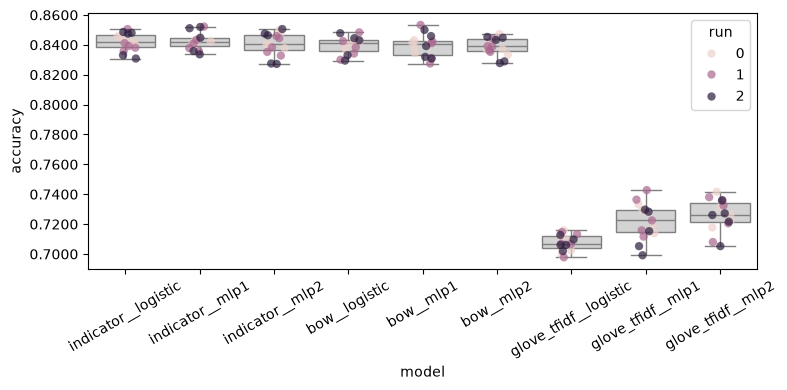

In [55]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [56]:
results_df = part1.analysis.make_data_frame(my_classifiers)
results_df.groupby("model")[["accuracy", "macro_f1"]].agg(["mean", "std", "count"]).sort_values(("accuracy", "mean"), ascending=False)

accuracy                  macro_f1                
                           mean       std count      mean       std count
model                                                                    
indicator__mlp1        0.842722  0.005750    15  0.805011  0.009901    15
indicator__logistic    0.841981  0.005851    15  0.808031  0.008939    15
indicator__mlp2        0.840685  0.007578    15  0.803979  0.010700    15
bow__logistic          0.839648  0.005895    15  0.805142  0.009839    15
bow__mlp1              0.839370  0.007280    15  0.800385  0.012125    15
bow__mlp2              0.838593  0.005823    15  0.801884  0.008387    15
glove_tfidf__mlp2      0.726093  0.010506    15  0.690688  0.011468    15
glove_tfidf__mlp1      0.722074  0.012003    15  0.684022  0.012086    15
glove_tfidf__logistic  0.707667  0.005488    15  0.666746  0.008244    15

In [57]:
# The full 3 x 3 grid is trained in the cross-validation cell above.
# Increase common_mlp_args["num_epochs"] after the two-epoch smoke test succeeds.

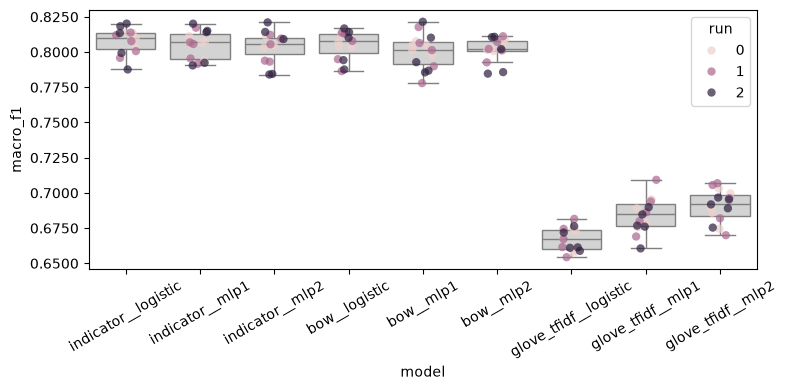

In [58]:
part1.analysis.plot_box_and_points(results_df, metric="macro_f1")

,mean_macro_f1,std_macro_f1,count
model,,,
indicator__logistic,0.808031,0.008939,15
bow__logistic,0.805142,0.009839,15
indicator__mlp1,0.805011,0.009901,15
indicator__mlp2,0.803979,0.010700,15
bow__mlp2,0.801884,0.008387,15
bow__mlp1,0.800385,0.012125,15
glove_tfidf__mlp2,0.690688,0.011468,15
glove_tfidf__mlp1,0.684022,0.012086,15
glove_tfidf__logistic,0.666746,0.008244,15


Reference system: indicator__logistic


,reference_mean,alternative_mean,P(reference better),P(equivalent),P(alternative better),posterior_mean_B_minus_A,effect_size,conclusion
alternative,,,,,,,,
bow__logistic,0.808031,0.805142,0.150028,8.493426e-01,6.298674e-04,-0.002889,-1.473080,Inconclusive
indicator__mlp1,0.808031,0.805011,0.183244,8.157455e-01,1.010725e-03,-0.003021,-1.424349,Inconclusive
indicator__mlp2,0.808031,0.803979,0.376486,6.193350e-01,4.178973e-03,-0.004053,-1.373160,Inconclusive
bow__mlp2,0.808031,0.801884,0.650416,3.486685e-01,9.152510e-04,-0.006148,-2.113369,Inconclusive
bow__mlp1,0.808031,0.800385,0.737261,2.589149e-01,3.823767e-03,-0.007646,-1.881600,Inconclusive
glove_tfidf__mlp2,0.808031,0.690688,1.000000,4.248379e-11,1.985101e-11,-0.117344,-17.415083,Reference better
glove_tfidf__mlp1,0.808031,0.684022,1.000000,1.707412e-12,8.523182e-13,-0.124009,-22.011031,Reference better
glove_tfidf__logistic,0.808031,0.666746,1.000000,3.042011e-14,1.842970e-14,-0.141286,-29.240212,Reference better


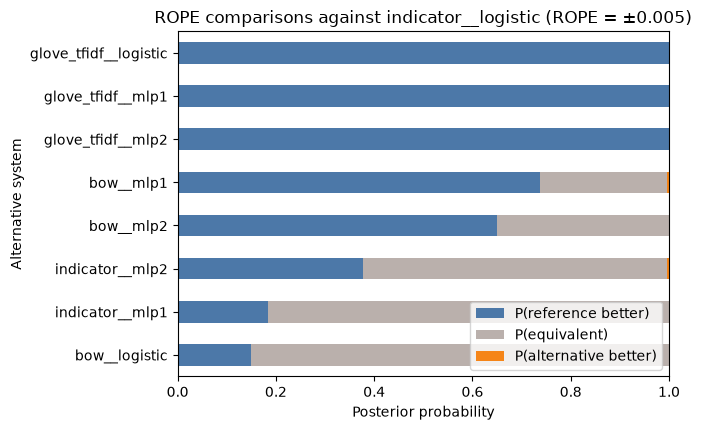

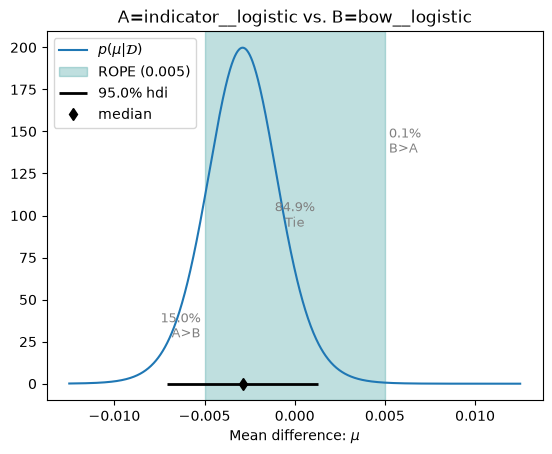

In [62]:
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

metric_key = "macro_f1_scores"
rope_size = 0.005  # differences below 0.5 macro-F1 percentage points are negligible
decision_threshold = 0.95

expected_systems = {
    f"{encoder}__{head}"
    for encoder, head in product(encoder_factories, head_configs)
}

def is_complete(system_name):
    runs = my_classifiers.get(system_name, [])
    return (
        len(runs) == len(my_seeds)
        and all(
            metric_key in run
            and len(run[metric_key]) == num_folds
            for run in runs
        )
    )

complete_systems = sorted(
    system for system in expected_systems
    if is_complete(system)
)
missing_systems = sorted(expected_systems.difference(complete_systems))

if missing_systems:
    print("Warning: incomplete systems are excluded:", missing_systems)
if len(complete_systems) < 2:
    raise RuntimeError("At least two complete systems are required for ROPE analysis.")

def get_measurements(system_name):
    return np.array([
        [
            run_data[metric_key][fold]
            for fold in sorted(run_data[metric_key])
        ]
        for run_data in my_classifiers[system_name]
    ])

summary_rows = []
for system in complete_systems:
    scores = get_measurements(system).flatten()
    summary_rows.append({
        "model": system,
        "mean_macro_f1": scores.mean(),
        "std_macro_f1": scores.std(ddof=1),
        "count": scores.size,
    })

rope_summary = (
    pd.DataFrame(summary_rows)
    .set_index("model")
    .sort_values("mean_macro_f1", ascending=False)
)
display(rope_summary)

reference = rope_summary.index[0]
reference_scores = get_measurements(reference)
comparison_rows = []
posteriors = {}

for alternative in rope_summary.index[1:]:
    alternative_scores = get_measurements(alternative)
    if alternative_scores.shape != reference_scores.shape:
        raise ValueError(
            f"Paired comparison requires matching shapes: "
            f"{reference_scores.shape} != {alternative_scores.shape}"
        )

    posterior = part1.analysis.BenavoliCorrelatedT(
        reference_scores.flatten(),
        alternative_scores.flatten(),
        runs=reference_scores.shape[0],
        names=[reference, alternative],
    )
    posteriors[alternative] = posterior
    p_reference, p_tie, p_alternative = posterior.probs(rope_size)

    if p_reference >= decision_threshold:
        conclusion = "Reference better"
    elif p_alternative >= decision_threshold:
        conclusion = "Alternative better"
    elif p_tie >= decision_threshold:
        conclusion = "Practically equivalent"
    else:
        conclusion = "Inconclusive"

    comparison_rows.append({
        "alternative": alternative,
        "reference_mean": rope_summary.loc[reference, "mean_macro_f1"],
        "alternative_mean": rope_summary.loc[alternative, "mean_macro_f1"],
        "P(reference better)": p_reference,
        "P(equivalent)": p_tie,
        "P(alternative better)": p_alternative,
        "posterior_mean_B_minus_A": posterior.mean_diff,
        "effect_size": posterior.effect_size,
        "conclusion": conclusion,
    })

rope_decisions = pd.DataFrame(comparison_rows).set_index("alternative")
print(f"Reference system: {reference}")
display(rope_decisions)

probability_columns = [
    "P(reference better)",
    "P(equivalent)",
    "P(alternative better)",
]
ax = rope_decisions[probability_columns].plot(
    kind="barh",
    stacked=True,
    figsize=(7, max(4, 0.55 * len(rope_decisions))),
    color=["#4C78A8", "#BAB0AC", "#F58518"],
)
ax.set_xlim(0, 1)
ax.set_xlabel("Posterior probability")
ax.set_ylabel("Alternative system")
ax.set_title(f"ROPE comparisons against {reference} (ROPE = ±{rope_size})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Show a detailed posterior for the second-highest observed mean.
closest_ranked_competitor = rope_summary.index[1]
_ = posteriors[closest_ranked_competitor].plot(rope_size)


,mean_macro_f1,std_macro_f1,measurements
model,,,
indicator__logistic,0.808031,0.008939,15
bow__logistic,0.805142,0.009839,15
indicator__mlp1,0.805011,0.009901,15
indicator__mlp2,0.803979,0.010700,15
bow__mlp2,0.801884,0.008387,15
bow__mlp1,0.800385,0.012125,15
glove_tfidf__mlp2,0.690688,0.011468,15
glove_tfidf__mlp1,0.684022,0.012086,15
glove_tfidf__logistic,0.666746,0.008244,15


Selected system from CV: indicator__logistic
Ensembling seed 0: 5 fold models
Test accuracy: 0.8525
Test macro-F1: 0.8095
Test micro-F1: 0.8525

              precision    recall  f1-score   support

     sadness     0.9373    0.8744    0.9047       581
         joy     0.9079    0.8647    0.8858       695
        love     0.6718    0.8239    0.7401       159
       anger     0.8204    0.8473    0.8336       275
        fear     0.7822    0.7857    0.7840       224
    surprise     0.6087    0.8485    0.7089        66

    accuracy                         0.8525      2000
   macro avg     0.7880    0.8407    0.8095      2000
weighted avg     0.8617    0.8525    0.8553      2000



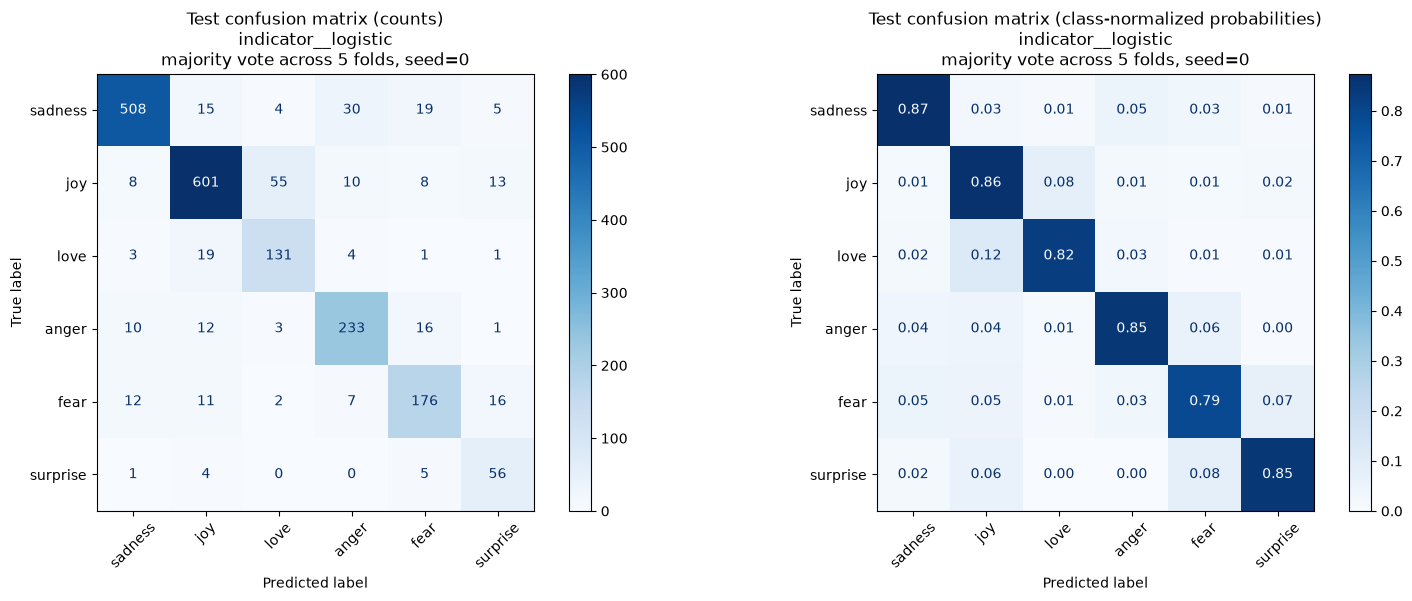

In [60]:
# Not necessary
# TODO: Check which words contribute to each class prediction.
# TODO: Make plot for training and valid error - check were it plateus.

# Necessay
# TODO: Re run the experiments, since we changed the dropouts.
# TODO: Understand GLOVE + TF-IDF

#Presentation
# TODO: Mention in the presentation choice of Word level over BPE + experimentation with cap of word level (1000 vs 2000)
# TODO: ADD 4 - 5 questions in the presentation
# TODO: Add the study about the word level tokenizer cap.



from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)

# Choose the final design using cross-validation only. For imbalanced classes,
# macro-F1 gives each emotion equal importance.
results_df = part1.analysis.make_data_frame(my_classifiers)
expected_measurements = len(my_seeds) * num_folds

cv_summary = (
    results_df
    .groupby("model")
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        measurements=("macro_f1", "count"),
    )
    .sort_values("mean_macro_f1", ascending=False)
)

complete_cv_summary = cv_summary[
    cv_summary["measurements"] == expected_measurements
]
incomplete_systems = cv_summary.index.difference(complete_cv_summary.index).tolist()

if incomplete_systems:
    print("Ignoring incomplete systems:", incomplete_systems)
if complete_cv_summary.empty:
    raise RuntimeError(
        f"No system has all {expected_measurements} CV measurements. "
        "Finish the cross-validation experiments before test evaluation."
    )

display(complete_cv_summary)
best_system = complete_cv_summary.index[0]
best_encoder_name, best_head_name = best_system.split("__", maxsplit=1)

# Use one seed fixed in advance, giving exactly five models (one per fold).
# Do not choose the seed after looking at test performance.
ensemble_seed = my_seeds[0]
ensemble_run = my_seeds.index(ensemble_seed)

test_texts = list(dataset["test"]["text"])
test_labels = np.asarray(dataset["test"]["label"])
predictions_by_fold = []

print(f"Selected system from CV: {best_system}")
print(f"Ensembling seed {ensemble_seed}: {num_folds} fold models")

for fold in range(num_folds):
    split = my_cross_validation_sets[ensemble_run][fold]
    fold_training_texts = [text for text, _ in split["training"]]

    # Reconstruct the encoder exactly as it was fitted for this fold. This is
    # essential for fold-specific TF-IDF statistics.
    fold_encoder = encoder_factories[best_encoder_name](fold_training_texts)
    model_path = Path(results_folder) / best_system / f"seed-{ensemble_seed}" / f"fold-{fold}" / "model"

    if best_head_name == "logistic":
        if not model_path.with_suffix(".pickle").exists():
            raise FileNotFoundError(f"Missing checkpoint: {model_path}.pickle")
        model = part1.loglin.load(str(model_path))
        fold_predictions = part1.loglin.predict(
            test_texts,
            model,
            fold_encoder,
        )
    else:
        missing_files = [
            path for path in (
                model_path.with_suffix(".json"),
                model_path.with_suffix(".pt"),
            )
            if not path.exists()
        ]
        if missing_files:
            raise FileNotFoundError(
                "Missing checkpoint file(s): "
                + ", ".join(map(str, missing_files))
            )
        model = part1.smlp.load(
            str(model_path),
            device=common_mlp_args.get("device", "cpu"),
        )
        probabilities = part1.smlp.predict_probs(
            test_texts,
            model,
            fold_encoder,
            batch_size=common_mlp_args.get("batch_size", 64),
        )
        fold_predictions = probabilities.argmax(axis=1)

    predictions_by_fold.append(np.asarray(fold_predictions, dtype=int))

# This is the batched equivalent of the tutorial's MajorityVoteClassifier.
# Random tie-breaking matches its behaviour; ties can occur in multiclass
# voting even with five models (for example, votes of 2-2-1).
fold_prediction_matrix = np.vstack(predictions_by_fold)
tie_rng = np.random.RandomState(0)
ensemble_predictions = []

for example_votes in fold_prediction_matrix.T:
    labels, counts = np.unique(example_votes, return_counts=True)
    winners = labels[counts == counts.max()]
    ensemble_predictions.append(tie_rng.choice(winners))

ensemble_predictions = np.asarray(ensemble_predictions, dtype=int)

test_accuracy = accuracy_score(test_labels, ensemble_predictions)
test_macro_f1 = f1_score(
    test_labels,
    ensemble_predictions,
    average="macro",
    zero_division=0,
)
test_micro_f1 = f1_score(
    test_labels,
    ensemble_predictions,
    average="micro",
    zero_division=0,
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")
print(f"Test micro-F1: {test_micro_f1:.4f}")
print()
print(
    classification_report(
        test_labels,
        ensemble_predictions,
        labels=list(range(len(outcome_space))),
        target_names=list(outcome_space),
        digits=4,
        zero_division=0,
    )
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(
    test_labels,
    ensemble_predictions,
    labels=list(range(len(outcome_space))),
    display_labels=list(outcome_space),
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=axes[0],
)
axes[0].set_title(
    f"Test confusion matrix (counts)\n{best_system}\n"
    f"majority vote across {num_folds} folds, seed={ensemble_seed}"
)

# Each row is normalized by the number of samples in its true class. Every
# cell is therefore P(predicted class | true class), and each row sums to 1.
ConfusionMatrixDisplay.from_predictions(
    test_labels,
    ensemble_predictions,
    labels=list(range(len(outcome_space))),
    display_labels=list(outcome_space),
    normalize="true",
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f",
    ax=axes[1],
)
axes[1].set_title(
    f"Test confusion matrix (class-normalized probabilities)\n{best_system}\n"
    f"majority vote across {num_folds} folds, seed={ensemble_seed}"
)

plt.tight_layout()
plt.show()



Top 5 positive-weight words per class for indicator__logistic, averaged across 5 folds (seed=0).


class,sadness,joy,love,anger,fear,surprise
rank,,,,,,
1,lethargic (+3.261),superior (+2.806),sympathetic (+4.695),offended (+3.854),pressured (+4.571),curious (+6.181)
2,unwelcome (+3.074),divine (+2.663),nostalgic (+4.657),resentful (+3.814),shaken (+4.348),impressed (+6.035)
3,troubled (+3.072),sincere (+2.601),horny (+4.531),irritable (+3.809),terrified (+4.141),amazed (+5.999)
4,groggy (+3.056),valued (+2.574),naughty (+4.451),rushed (+3.732),vulnerable (+4.131),dazed (+5.849)
5,melancholy (+3.053),convinced (+2.573),fond (+4.408),dangerous (+3.647),apprehensive (+4.054),surprised (+5.748)


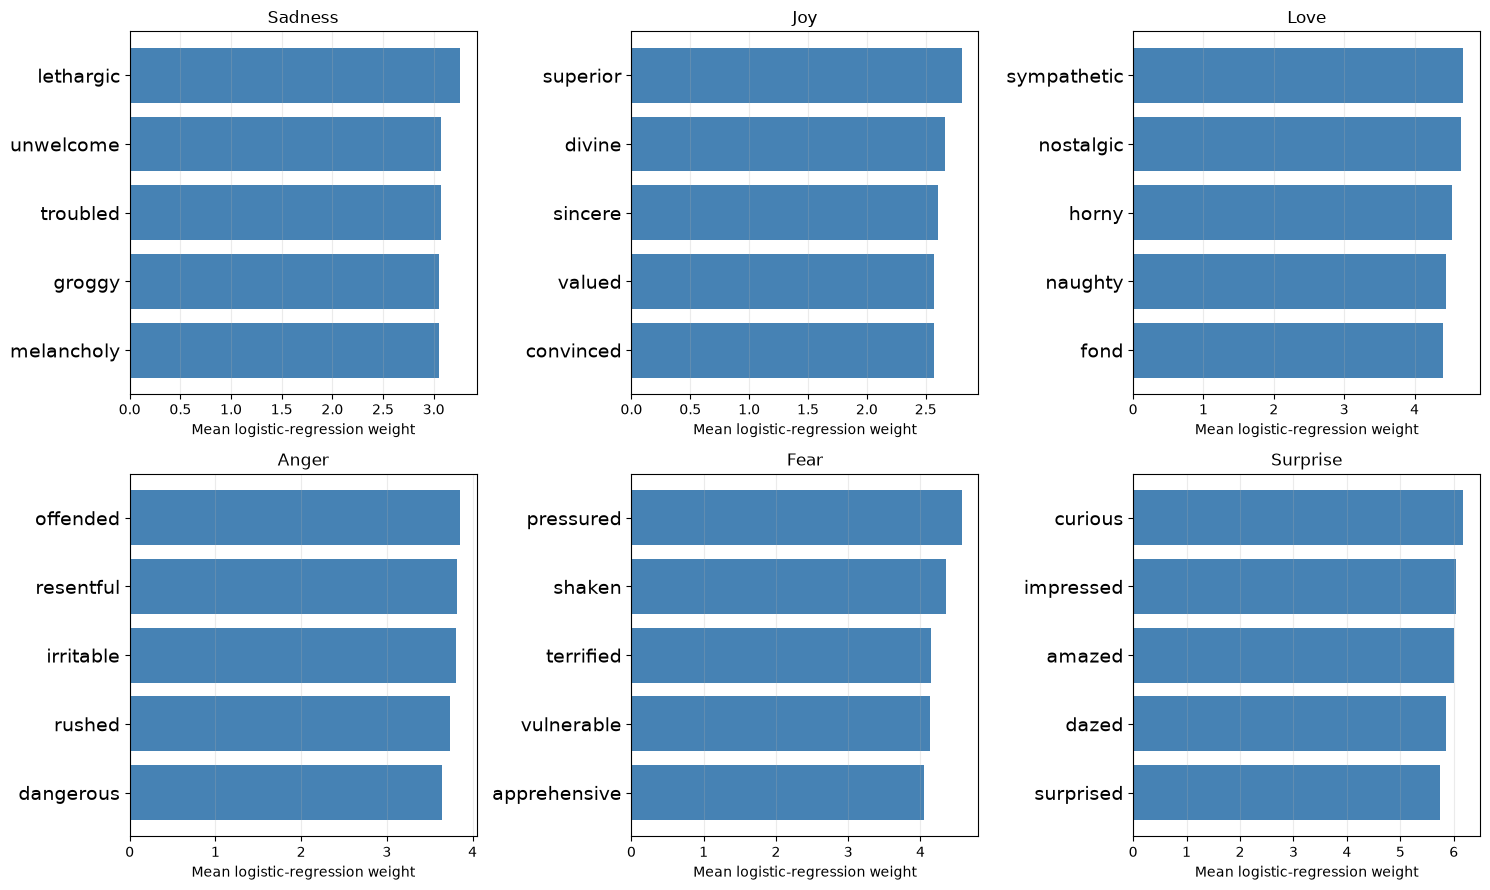

Interpretation: a larger positive coefficient means that the presence of the word increases that class's logit, holding the other indicator features fixed. This is an association, not a causal effect.


In [66]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Number of highest positive-weight words to show for each emotion.
top_k = 5
word_font_size = 14

if not isinstance(top_k, int) or top_k < 1:
    raise ValueError("top_k must be a positive integer")

interpretation_system = "indicator__logistic"
interpretation_seed = my_seeds[0]
coefficient_matrices = []

# The final system uses five fold models. Their features have identical token
# IDs, so their coefficients can be averaged to obtain a more stable ranking.
for fold in range(num_folds):
    model_path = (
        Path(results_folder)
        / interpretation_system
        / f"seed-{interpretation_seed}"
        / f"fold-{fold}"
        / "model"
    )
    checkpoint = model_path.with_suffix(".pickle")
    if not checkpoint.exists():
        raise FileNotFoundError(f"Missing checkpoint: {checkpoint}")

    fold_model = part1.loglin.load(str(model_path))
    coefficient_matrices.append(fold_model.coef_)

coefficient_shapes = {matrix.shape for matrix in coefficient_matrices}
if len(coefficient_shapes) != 1:
    raise ValueError(
        f"Fold coefficient shapes do not match: {sorted(coefficient_shapes)}"
    )

mean_coefficients = np.mean(coefficient_matrices, axis=0)
vocabulary = tokenizer.get_vocab()  # token -> feature ID
id_to_token = {token_id: token for token, token_id in vocabulary.items()}

if mean_coefficients.shape != (len(outcome_space), len(vocabulary)):
    raise ValueError(
        "Unexpected coefficient shape: "
        f"{mean_coefficients.shape}; expected "
        f"({len(outcome_space)}, {len(vocabulary)})"
    )

# Keep actual word-like tokens and exclude the unknown/special token.
candidate_token_ids = [
    token_id
    for token_id, token in id_to_token.items()
    if token != "??" and any(character.isalnum() for character in token)
]

rows = []
for class_id, class_name in enumerate(outcome_space.names):
    ranked_token_ids = sorted(
        candidate_token_ids,
        key=lambda token_id: mean_coefficients[class_id, token_id],
        reverse=True,
    )[:top_k]

    for rank, token_id in enumerate(ranked_token_ids, start=1):
        rows.append({
            "class": class_name,
            "rank": rank,
            "word": id_to_token[token_id],
            "mean_weight": mean_coefficients[class_id, token_id],
        })

top_words_df = pd.DataFrame(rows)

# Compact table: each entry contains the word and its mean coefficient.
top_words_table = (
    top_words_df
    .assign(
        word_and_weight=lambda frame: frame.apply(
            lambda row: f"{row['word']} ({row['mean_weight']:+.3f})",
            axis=1,
        )
    )
    .pivot(index="rank", columns="class", values="word_and_weight")
    .reindex(columns=list(outcome_space.names))
)

print(
    f"Top {top_k} positive-weight words per class for {interpretation_system}, "
    f"averaged across {num_folds} folds (seed={interpretation_seed})."
)
display(top_words_table)

# Visual version of the same rankings.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, class_name in zip(axes.flat, outcome_space.names):
    class_rows = (
        top_words_df[top_words_df["class"] == class_name]
        .sort_values("mean_weight")
    )
    axis.barh(
        class_rows["word"],
        class_rows["mean_weight"],
        color="steelblue",
    )
    axis.set_title(class_name.title())
    axis.set_xlabel("Mean logistic-regression weight")
    axis.tick_params(axis="y", labelsize=word_font_size)
    axis.grid(axis="x", alpha=0.25)

# fig.suptitle(
#     f"Top {top_k} words associated with each emotion\n"
#     f"{interpretation_system}, mean across {num_folds} folds",
#     fontsize=15,
# )
plt.tight_layout()
plt.show()

print(
    "Interpretation: a larger positive coefficient means that the presence "
    "of the word increases that class's logit, holding the other indicator "
    "features fixed. This is an association, not a causal effect."
)

